# Customer Return-Risk Feature Engineering

## tl;dr

This notebook converts historical transactions into point-in-time customer snapshots. Every feature stops before its observation date, while the label uses the following 90 days. A 90-day purge between evaluation blocks prevents training labels from using purchases that occur after validation features.

## Context & Methods

The business question is: **which known customers are likely to purchase again during the next 90 days?** The prediction is an estimated likelihood, not proof that a customer has permanently churned.

```text
historical transactions → observation date → 90-day outcome window
       features stop here ↑                 ↑ target only
```

### Key assumptions

- Only customers with at least 90 days of observed history are eligible.
- Anonymous purchases cannot support customer-level prediction.
- A valid future sale counts as a return; cancellations do not.
- Customer ID identifies rows but is never a model feature.
- The test file remains sealed until the final-test notebook.

In [1]:
from pathlib import Path
import json
import sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.return_risk_features import assert_no_temporal_leakage
sns.set_theme(style='whitegrid')
pd.options.display.max_columns = 60
pd.options.display.float_format = '{:,.3f}'.format

## Data

### 1. Load development partitions only

In [2]:
train = pd.read_parquet(ROOT / 'data/processed/return_risk_train.parquet')
validation = pd.read_parquet(ROOT / 'data/processed/return_risk_validation.parquet')
metadata = json.loads((ROOT / 'data/processed/return_risk_split_metadata.json').read_text())
print(f'Training snapshots: {len(train):,}')
print(f'Validation snapshots: {len(validation):,}')
print('The final test partition is intentionally not loaded.')

Training snapshots: 23,974
Validation snapshots: 4,315
The final test partition is intentionally not loaded.


### 2. Confirm target and snapshot grain

In [3]:
target = 'returned_within_90_days'
assert train['snapshot_id'].is_unique
assert validation['snapshot_id'].is_unique
assert set(train[target].unique()).issubset({0, 1})
assert set(validation[target].unique()).issubset({0, 1})
grain = pd.Series({
 'training snapshots': len(train),
 'training customers': train['customer_id'].nunique(),
 'training observation dates': train['observation_date'].nunique(),
 'validation snapshots': len(validation),
 'validation customers': validation['customer_id'].nunique(),
 'validation observation dates': validation['observation_date'].nunique(),
})
display(grain.to_frame('count'))

,count
training snapshots,23974
training customers,3475
training observation dates,10
validation snapshots,4315
validation customers,4315
validation observation dates,1


## Feature Engineering

### 3. Review the model feature catalogue

Lifetime features summarize all valid history before the observation date. Window features describe only the most recent 30, 60, 90, or 180 days.

In [4]:
excluded = {'customer_id','snapshot_id','observation_date','outcome_end','first_purchase','last_purchase',target}
model_features = [column for column in train.columns if column not in excluded]
feature_groups = {
 'Customer context': ['primary_country'],
 'Recency and tenure': ['recency_days','tenure_days'],
 'Lifetime behaviour': [c for c in model_features if c.endswith('_lifetime')],
 'Order behaviour': ['average_order_value','average_basket_units','order_value_std','orders_per_30_days'],
 'Recent windows': [c for c in model_features if c.endswith(('30d','60d','90d','180d'))],
 'Behaviour change': ['recent_revenue_change','recent_order_change'],
 'Return history': ['historical_return_value_rate'],
}
catalogue = pd.DataFrame(
 [(group, feature) for group, features in feature_groups.items() for feature in features],
 columns=['feature_group','feature']
)
display(catalogue)
catalogue.to_csv(ROOT / 'reports/generated/return_risk_feature_catalogue.csv', index=False)
print(f'Model features: {len(model_features)}')

,feature_group,feature
0,Customer context,primary_country
1,Recency and tenure,recency_days
2,Recency and tenure,tenure_days
3,Lifetime behaviour,orders_lifetime
4,Lifetime behaviour,revenue_lifetime
5,Lifetime behaviour,units_lifetime
6,Lifetime behaviour,products_lifetime
7,Lifetime behaviour,cancellation_lines_lifetime
8,Lifetime behaviour,returned_value_lifetime
9,Order behaviour,average_order_value


Model features: 28


### 4. Inspect feature completeness and distributions

In [5]:
feature_quality = pd.DataFrame({
 'dtype': train[model_features].dtypes.astype(str),
 'missing_rate': train[model_features].isna().mean(),
 'distinct_values': train[model_features].nunique(dropna=True),
}).sort_values(['missing_rate','distinct_values'], ascending=[False,True])
display(feature_quality)
numeric = train[model_features].select_dtypes(include='number').columns.tolist()
display(train[numeric].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)

,dtype,missing_rate,distinct_values
order_value_std,float64,0.282,7947
orders_30d,float64,0.000,28
primary_country,string,0.000,35
orders_60d,float64,0.000,38
orders_90d,float64,0.000,49
recent_order_change,float64,0.000,51
orders_180d,float64,0.000,72
cancellation_lines_lifetime,float64,0.000,95
orders_lifetime,int64,0.000,106
tenure_days,int64,0.000,290


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
orders_lifetime,"23,974.000",4.341,7.057,1.000,1.000,1.000,3.000,5.000,12.000,32.000,188.000
revenue_lifetime,"23,974.000","2,028.160","8,276.647",1.300,38.048,320.790,758.700,"1,729.540","6,001.740","20,163.972","376,998.960"
units_lifetime,"23,974.000","1,327.170","6,927.304",1.000,14.000,168.000,418.500,999.000,"3,420.700","13,431.500","220,596.000"
products_lifetime,"23,974.000",62.209,81.175,1.000,1.000,18.000,38.000,78.000,193.000,362.540,"1,752.000"
average_order_value,"23,974.000",373.330,416.431,1.300,30.650,180.450,294.000,426.690,907.162,"1,952.640","10,877.180"
average_basket_units,"23,974.000",251.235,"1,079.079",1.000,11.438,88.500,154.134,263.750,583.783,"1,341.146","44,119.200"
order_value_std,"17,225.000",209.011,390.854,0.000,2.425,61.637,124.369,231.422,588.942,"1,506.488","8,810.330"
recency_days,"23,974.000",94.133,84.542,0.000,0.000,23.000,71.000,143.000,264.000,341.000,389.000
tenure_days,"23,974.000",212.881,80.464,90.000,92.000,144.000,203.000,271.000,357.000,387.000,389.000
orders_per_30_days,"23,974.000",0.606,0.804,0.077,0.091,0.235,0.404,0.698,1.601,3.768,14.540


### 5. Show why transformations belong inside the model pipeline

Revenue, frequency, and basket variables have long right tails. They are not deleted as outliers because high-value customers are commercially meaningful. Imputation, scaling, and any transformation must be fitted on training data only.

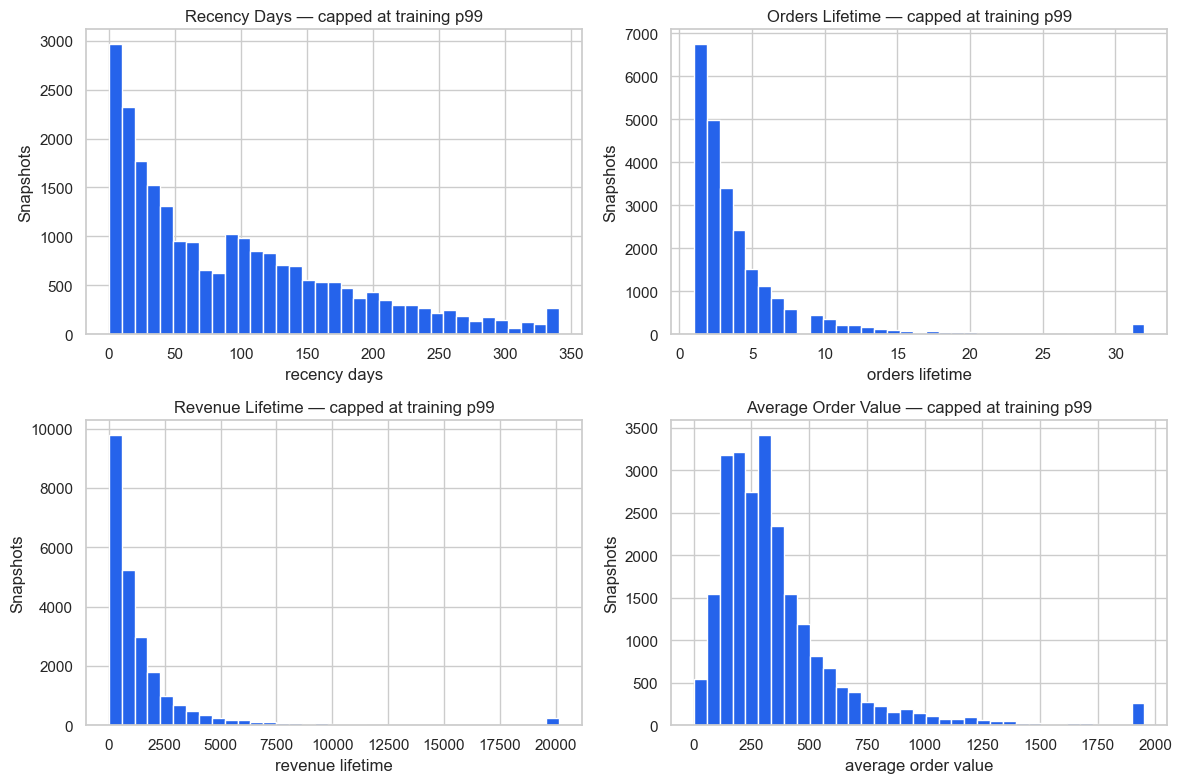

In [6]:
plot_features = ['recency_days','orders_lifetime','revenue_lifetime','average_order_value']
fig, axes = plt.subplots(2,2,figsize=(12,8))
for feature, ax in zip(plot_features, axes.flat):
    train[feature].clip(upper=train[feature].quantile(.99)).hist(bins=35, ax=ax, color='#2563EB')
    ax.set_title(f'{feature.replace("_"," ").title()} — capped at training p99')
    ax.set_xlabel(feature.replace('_',' ')); ax.set_ylabel('Snapshots')
plt.tight_layout(); plt.show()

## Chronological Splitting

### 6. Inspect periods and class balance

,partition,rows,start,end,return_rate
0,Training,23974,2010-03-31,2010-12-26,0.496
1,Validation,4315,2011-03-26,2011-03-26,0.354


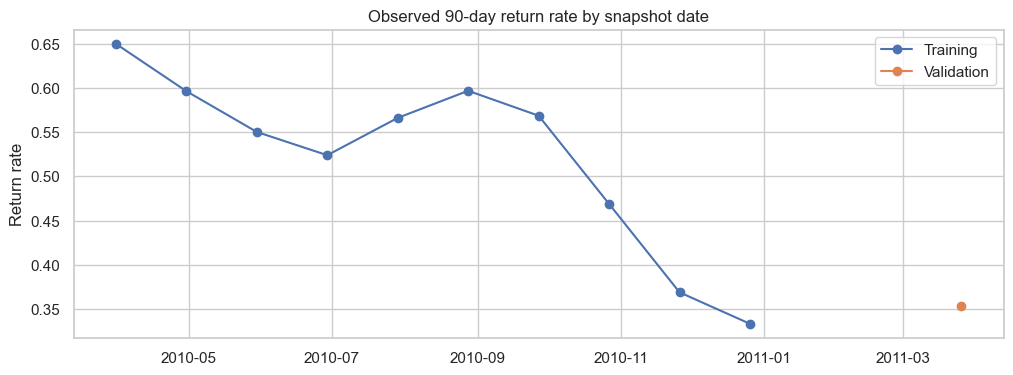

In [7]:
split_summary = pd.DataFrame([
 {'partition':'Training','rows':len(train),'start':train['observation_date'].min(),'end':train['observation_date'].max(),'return_rate':train[target].mean()},
 {'partition':'Validation','rows':len(validation),'start':validation['observation_date'].min(),'end':validation['observation_date'].max(),'return_rate':validation[target].mean()},
])
display(split_summary)
balance = pd.concat([
 train.assign(partition='Training'), validation.assign(partition='Validation')
]).groupby(['observation_date','partition'])[target].mean().reset_index()
fig, ax = plt.subplots(figsize=(12,4))
for name, frame in balance.groupby('partition'):
    ax.plot(frame['observation_date'], frame[target], marker='o', label=name)
ax.set(title='Observed 90-day return rate by snapshot date', xlabel='', ylabel='Return rate')
ax.legend(); plt.show()

### 7. Explain why the final row shares are not exactly 70/15/15

Cut points begin from a chronological 70/15/15 design. Rows near each boundary are then purged when their 90-day outcomes overlap the next partition. Customer volume also grows over time. Preserving exact row percentages would be less important than preventing look-ahead.

In [8]:
display(pd.Series(metadata, name='value').to_frame())
print('Training maximum outcome end:', train['outcome_end'].max())
print('Validation minimum observation:', validation['observation_date'].min())
print('Validation maximum outcome end:', validation['outcome_end'].max())

,value
validation_start,2011-03-26T00:00:00
test_start,2011-06-24T00:00:00
train_max_outcome_end,2011-03-26T00:00:00
validation_max_outcome_end,2011-06-24T00:00:00


Training maximum outcome end: 2011-03-26 00:00:00
Validation minimum observation: 2011-03-26 00:00:00
Validation maximum outcome end: 2011-06-24 00:00:00


## Leakage Audit

### 8. Execute temporal leakage assertions

In [9]:
# A minimal sealed placeholder supplies only the test boundary required by the assertion.
sealed_test_boundary = pd.DataFrame({
 'observation_date': [pd.Timestamp(metadata['test_start'])],
 'outcome_end': [pd.Timestamp(metadata['test_start']) + pd.Timedelta(days=90)],
 'last_purchase': [pd.Timestamp(metadata['test_start']) - pd.Timedelta(days=1)],
})
assert_no_temporal_leakage(train, validation, sealed_test_boundary)
assert train['last_purchase'].lt(train['observation_date']).all()
assert validation['last_purchase'].lt(validation['observation_date']).all()
assert train['outcome_end'].le(validation['observation_date'].min()).all()
assert validation['outcome_end'].le(pd.Timestamp(metadata['test_start'])).all()
print('PASS — features stop before observation dates.')
print('PASS — training outcomes end before validation begins.')
print('PASS — validation outcomes end before the sealed test boundary.')

PASS — features stop before observation dates.
PASS — training outcomes end before validation begins.
PASS — validation outcomes end before the sealed test boundary.


### 9. Confirm forbidden fields are excluded from modelling

In [10]:
forbidden = {'customer_id','snapshot_id','observation_date','outcome_end','first_purchase','last_purchase',target}
assert forbidden.isdisjoint(model_features)
display(pd.DataFrame({'excluded_field': sorted(forbidden), 'reason': [
 'Entity identifier, not behaviour','Row identifier','Split/control timestamp', 'Outcome boundary','Raw timestamp summarized safely','Raw timestamp summarized safely', 'Prediction target']
}))

,excluded_field,reason
0,customer_id,"Entity identifier, not behaviour"
1,first_purchase,Row identifier
2,last_purchase,Split/control timestamp
3,observation_date,Outcome boundary
4,outcome_end,Raw timestamp summarized safely
5,returned_within_90_days,Raw timestamp summarized safely
6,snapshot_id,Prediction target


## Takeaways

- The modelling unit is one customer at one observation date.
- Twenty-eight behavioural features are available before prediction time.
- Customer identifiers and raw control dates are excluded from the model.
- Boundary purging is more important than exact partition percentages.
- The test dataset exists as a sealed file and is not loaded here.
- Differences in return rate over time mean shuffled cross-validation would be misleading.